### **Single Contract Retrieval**

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime, timezone, timedelta

# Kalshi API base URL
BASE_URL = "https://external-api.kalshi.com/trade-api/v2"

##### **Test API connection**

In [2]:
# API endpoint
url = f"{BASE_URL}/markets"

# Request parameters
params = {
    "limit": 10,
    "status": "open"
}

# Send GET request
response = requests.get(url, params=params, timeout=30)

# Check response
print("Status code:", response.status_code)

# Convert response to JSON
data = response.json()

# Display the first market
data["markets"][0]

Status code: 200


{'can_close_early': True,
 'close_time': '2026-11-23T15:00:00Z',
 'created_time': '2026-11-09T16:30:37.692847Z',
 'custom_strike': {'Associated Events': 'KXATPCHALLENGERMATCH-26NOV09HEMPOU,KXATPCHALLENGERMATCH-26NOV09MARPLA,KXNBAGAME-26NOV09CLECHA,KXNBAGAME-26NOV09DENHOU,KXNBAGAME-26NOV09INDDAL,KXNBAGAME-26NOV09LALATL,KXNBAGAME-26NOV09MEMTOR,KXNBAGAME-26NOV09NOPGSW,KXNBAGAME-26NOV09SASPHX,KXNBAGAME-26NOV09WASDET,KXNBATOTAL-26NOV09CLECHA,KXNBATOTAL-26NOV09DENHOU,KXNBATOTAL-26NOV09INDDAL,KXNBATOTAL-26NOV09LALATL,KXNBATOTAL-26NOV09MEMTOR,KXNBATOTAL-26NOV09NOPGSW,KXNBATOTAL-26NOV09WASDET,KXNFLGAME-26NOV09BUFMIN,KXNHLGAME-26NOV09NYISJ',
  'Associated Market Sides': 'yes,yes,yes,yes,yes,yes,yes,yes,yes,yes,no,yes,no,no,yes,no,no,yes,yes',
  'Associated Markets': 'KXATPCHALLENGERMATCH-26NOV09HEMPOU-POU,KXATPCHALLENGERMATCH-26NOV09MARPLA-MAR,KXNBAGAME-26NOV09CLECHA-CLE,KXNBAGAME-26NOV09DENHOU-HOU,KXNBAGAME-26NOV09INDDAL-DAL,KXNBAGAME-26NOV09LALATL-ATL,KXNBAGAME-26NOV09MEMTOR-MEM,KXNBAGAME-26NO

##### **Retreive sample of historical contracts**

In [3]:
# Retrieve a sample of archived historical markets

url = f"{BASE_URL}/historical/markets"

params = {
    "limit": 100
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)

response.raise_for_status()

historical_data = response.json()

historical_markets_df = pd.DataFrame(
    historical_data["markets"]
)

print("Historical markets retrieved:", len(historical_markets_df))

display(historical_markets_df.head())

Status code: 200
Historical markets retrieved: 100


,can_close_early,close_time,created_time,custom_strike,event_ticker,exchange_index,expected_expiration_time,expiration_time,expiration_value,last_price_dollars,...,ticker,title,updated_time,volume_24h_fp,volume_fp,yes_ask_dollars,yes_ask_size_fp,yes_bid_dollars,yes_bid_size_fp,yes_sub_title
0,True,2026-09-09T23:56:15Z,2026-09-09T23:45:23.866515Z,{'Associated Events': 'KXMLBF3-26SEP091840HOUP...,KXMVECROSSCATEGORY-SHARD1-S2026291E332C297,1,2026-09-10T05:15:00Z,2026-09-12T23:15:00Z,,0.0014,...,KXMVECROSSCATEGORY-SHARD1-S2026291E332C297-609...,"yes Houston wins first 3 innings,yes Atlanta w...",2026-09-09T23:56:25.628573Z,0.00,6666.66,1.0000,0.00,0.0000,0.00,"yes Houston wins first 3 innings,yes Atlanta w..."
1,True,2026-09-09T23:56:15Z,2026-09-09T23:44:15.454112Z,{'Associated Events': 'KXMLBF3-26SEP091840HOUP...,KXMVECROSSCATEGORY-SHARD1-S20261B6C7D22794,1,2026-09-10T08:10:00Z,2026-09-13T02:10:00Z,,0.0025,...,KXMVECROSSCATEGORY-SHARD1-S20261B6C7D22794-446...,"yes Houston wins first 3 innings,yes Los Angel...",2026-09-09T23:56:25.628573Z,0.00,3703.70,1.0000,0.00,0.0000,0.00,"yes Houston wins first 3 innings,yes Los Angel..."
2,True,2026-09-09T23:45:00Z,2026-09-09T23:43:39.561975Z,"{'Associated Events': 'KXBNB15M-26SEP091945,KX...",KXMVECROSSCATEGORY-SHARD1-S2026FB107B612D4,1,2026-09-10T05:30:00Z,2026-09-09T23:45:00Z,,0.0009,...,KXMVECROSSCATEGORY-SHARD1-S2026FB107B612D4-2E6...,"yes Target Price: $721.25,yes Target Price: $7...",2026-09-09T23:45:35.624949Z,0.00,1000.00,1.0000,0.00,0.0000,0.00,"yes Target Price: $721.25,yes Target Price: $7..."
3,True,2026-09-09T23:45:00Z,2026-09-09T23:43:36.274553Z,"{'Associated Events': 'KXBNB15M-26SEP091945,KX...",KXMVECROSSCATEGORY-SHARD1-S2026E3D38812C43,1,2026-09-10T05:30:00Z,2026-09-09T23:45:00Z,,0.9470,...,KXMVECROSSCATEGORY-SHARD1-S2026E3D38812C43-BB1...,"yes Target Price: $721.25,yes Target Price: $7...",2026-09-09T23:45:35.624949Z,0.00,6.30,1.0000,0.00,0.0000,0.00,"yes Target Price: $721.25,yes Target Price: $7..."
4,True,2026-09-09T23:56:15Z,2026-09-09T23:42:38.148664Z,{'Associated Events': 'KXMLBF3-26SEP091840HOUP...,KXMVECROSSCATEGORY-SHARD1-S2026533D0646338,1,2026-09-10T08:10:00Z,2026-09-13T02:10:00Z,,0.0560,...,KXMVECROSSCATEGORY-SHARD1-S2026533D0646338-A4C...,"yes Philadelphia wins first 3 innings,yes New ...",2026-09-09T23:56:25.628573Z,0.00,418.06,1.0000,0.00,0.0000,0.00,"yes Philadelphia wins first 3 innings,yes New ..."


##### **Retrieve series metadata**

In [4]:
# Retrieve Kalshi series metadata

url = f"{BASE_URL}/series"

params = {
    "include_volume": "true"
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

response.raise_for_status()

series_data = response.json()

series_df = pd.DataFrame(series_data["series"])

print("Total series retrieved:", len(series_df))

display(series_df.head())

Total series retrieved: 15956


,additional_prohibitions,categories,category,contract_terms_url,contract_url,exchange_index,fee_multiplier,fee_type,frequency,last_updated_ts,settlement_sources,tags,ticker,title,volume_fp
0,[Persons who are employed by any of the Source...,[Entertainment],Entertainment,https://assets.kalshi.com/contract_terms/TOPAL...,https://assets.kalshi.com/regulatory/product-c...,0,1.0,quadratic,one_off,2026-10-15T08:14:10.229686Z,"[{'name': 'Billboard', 'url': 'https://www.bil...","[Music, Music charts]",KXTOPALBUMTHEROMANTIC,WILL THE ROMANTIC BY BRUNO MARS BE NUMBER 1,771203.00
1,[Persons who are employed by any of the Source...,[Entertainment],Entertainment,https://assets.kalshi.com/contract_terms/COMPE...,https://assets.kalshi.com/regulatory/product-c...,0,1.0,quadratic,one_off,2026-11-05T21:38:04.812259Z,[{'name': 'the official broadcaster or stream...,"[Reality TV, Television]",KXTRAITORS,WHO WILL WIN TRAITORS,4232341.00
2,[Persons who are employed by any of the Source...,[Elections],Elections,https://assets.kalshi.com/contract_terms/ELECT...,https://assets.kalshi.com/regulatory/product-c...,0,1.0,quadratic,one_off,2026-11-03T19:14:44.508103Z,"[{'name': 'Elections Quebec', 'url': 'https://...","[International elections, International]",KXQUEBEC5TH,Quebec general election: 5th place,17244.00
3,[Persons who are employed by any of the Source...,[Entertainment],Entertainment,https://assets.kalshi.com/contract_terms/MARRI...,https://assets.kalshi.com/regulatory/product-c...,0,1.0,quadratic,one_off,2026-10-15T08:14:10.229686Z,"[{'name': 'The Washington Post', 'url': 'https...",[People],KXMARRIAGEBELICHICKHUDSON,WILL BILL BELICHICK AND JORDAN HUDSON BE MARRIED,13444.00
4,[Persons who are employed by any of the Source...,[Elections],Elections,https://assets.kalshi.com/contract_terms/GOVHE...,https://assets.kalshi.com/regulatory/product-c...,0,1.0,quadratic,one_off,2026-10-23T15:37:11.612369Z,"[{'name': 'parliament or legislature of ', 'ur...",[International elections],KXNEXTDUTCHPM,next Dutch prime minister,78754.00


##### **Examine available categories**

In [5]:
# Examine the categories represented in Kalshi's series

category_counts = (
    series_df["categories"]
    .explode()
    .value_counts()
)

display(category_counts)

categories
Sports                    4157
Entertainment             2609
Elections                 2481
Politics                  2425
Financials                1154
Economics                  878
Climate and Weather        501
Mentions                   465
Science and Technology     406
Crypto                     294
Companies                  216
Commodities                146
World                      143
Health                      95
Social                      48
Transportation              37
Exotics                     14
Culture                      2
Business                     1
Education                    1
Name: count, dtype: int64

In [6]:
# Define research categories
target_categories = [
    "Politics",
    "Elections",
    "Financials",
    "Economics",
    "Companies",
    "Commodities",
    "World",
    "Climate and Weather"
]

# Filter series by category
relevant_series_df = series_df[
    series_df["category"].isin(target_categories)
].copy()

# Sort by trading volume
relevant_series_df = relevant_series_df.sort_values(
    "volume_fp",
    ascending=False
)

print("Total relevant series:", len(relevant_series_df))

display(
    relevant_series_df[[
        "ticker",
        "title",
        "category",
        "tags",
        "volume_fp"
    ]].head(50)
)

Total relevant series: 7852


,ticker,title,category,tags,volume_fp
10064,KXWALZGOV,Walz Run Governor,Elections,[US Elections],9992.00
7415,KXGERMANGOVT,Length of German coalition-building,Politics,None,99903.00
10383,KXLOWTMIA,Lowest temperature in Miami,Climate and Weather,[Daily temperature],9987593.00
15460,KXMTLHOME,Montreal single-family home price below X in [...,Economics,[Housing],9985.00
10391,KXHEGSETHCOUNT,Hegseth Senate Yeas,Politics,[Congress],997955.00
966,KXRAINELECTION,Rain on Election Day,Climate and Weather,[Events],99604.00
12873,KXTRUMPVISITSTATES,b.,Politics,[International],99584.00
6701,KXLOWTCHI,Lowest Temperature Chicago,Climate and Weather,[Daily temperature],9952778.00
6978,KXSCHWA,Charles Schwab KPI,Financials,[KPIs],995.00
4203,KXNEXTIRANLEADER,Who will be Khamenei's successor?,Elections,[Iran],9946642.00


##### **Retrieve contracts belonging to a selected series sample**

In [7]:
# Select a relevant series
selected_series_ticker = "KXSHUTDOWNBYDATE"

url = f"{BASE_URL}/historical/markets"

params = {
    "limit": 100,
    "series_ticker": selected_series_ticker
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)

# Display the API response if something goes wrong
if response.status_code != 200:
    print("Error details:", response.text)
else:
    series_history = response.json()

    series_markets_df = pd.DataFrame(
        series_history["markets"]
    )

    print(
        "Historical contracts retrieved:",
        len(series_markets_df)
    )

    display(series_markets_df.head())

Status code: 200
Historical contracts retrieved: 1


,can_close_early,close_time,created_time,early_close_condition,event_ticker,exchange_index,expected_expiration_time,expiration_time,expiration_value,last_price_dollars,...,ticker,title,updated_time,volume_24h_fp,volume_fp,yes_ask_dollars,yes_ask_size_fp,yes_bid_dollars,yes_bid_size_fp,yes_sub_title
0,True,2025-03-18T14:00:00Z,2025-03-03T20:11:08.869458Z,"If this event occurs, the market will close th...",KXSHUTDOWNBYDATE-25MAR18,0,2025-03-18T14:00:00Z,2025-03-25T14:00:00Z,No,0.0100,...,KXSHUTDOWNBYDATE-25MAR18,"Government shutdown before Mar 19, 2025?",2026-02-19T08:48:16.628714Z,0.00,2280430.00,0.0100,0.00,0.0000,0.00,"Before Mar 19, 2025"


##### **Filter out multivariate contracts**

In [8]:
# Remove multivariate event contracts
if "mve_collection_ticker" in series_markets_df.columns:

    individual_contracts_df = series_markets_df[
        series_markets_df["mve_collection_ticker"].isna()
    ].copy()

else:
    individual_contracts_df = series_markets_df.copy()

print("Contracts before filtering:", len(series_markets_df))
print("Individual contracts:", len(individual_contracts_df))

display(individual_contracts_df.head())

Contracts before filtering: 1
Individual contracts: 1


,can_close_early,close_time,created_time,early_close_condition,event_ticker,exchange_index,expected_expiration_time,expiration_time,expiration_value,last_price_dollars,...,ticker,title,updated_time,volume_24h_fp,volume_fp,yes_ask_dollars,yes_ask_size_fp,yes_bid_dollars,yes_bid_size_fp,yes_sub_title
0,True,2025-03-18T14:00:00Z,2025-03-03T20:11:08.869458Z,"If this event occurs, the market will close th...",KXSHUTDOWNBYDATE-25MAR18,0,2025-03-18T14:00:00Z,2025-03-25T14:00:00Z,No,0.0100,...,KXSHUTDOWNBYDATE-25MAR18,"Government shutdown before Mar 19, 2025?",2026-02-19T08:48:16.628714Z,0.00,2280430.00,0.0100,0.00,0.0000,0.00,"Before Mar 19, 2025"


##### **Check Contract Results**

In [9]:
display(
    individual_contracts_df[[
        "ticker",
        "event_ticker",
        "title",
        "status",
        "result",
        "volume_fp",
        "settlement_ts"
    ]].head(20)
)

,ticker,event_ticker,title,status,result,volume_fp,settlement_ts
0,KXSHUTDOWNBYDATE-25MAR18,KXSHUTDOWNBYDATE-25MAR18,"Government shutdown before Mar 19, 2025?",finalized,no,2280430.00,2025-03-18T20:24:31.132506Z


##### **Retrieve candlesticks**

In [10]:
# Select our historical market
market_ticker = individual_contracts_df.iloc[0]["ticker"]

# Get the contract's creation and settlement dates
market_created = pd.to_datetime(
    individual_contracts_df.iloc[0]["created_time"],
    utc=True
)

market_settled = pd.to_datetime(
    individual_contracts_df.iloc[0]["settlement_ts"],
    utc=True
)

# Convert dates to Unix timestamps
start_ts = int(market_created.timestamp())
end_ts = int(market_settled.timestamp())

# Historical candlestick endpoint
url = f"{BASE_URL}/historical/markets/{market_ticker}/candlesticks"

params = {
    "start_ts": start_ts,
    "end_ts": end_ts,
    "period_interval": 60
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

print("Status code:", response.status_code)

response.raise_for_status()

candlestick_data = response.json()

candlesticks_df = pd.DataFrame(
    candlestick_data["candlesticks"]
)

print("Candlesticks retrieved:", len(candlesticks_df))

display(candlesticks_df.head())

Status code: 200
Candlesticks retrieved: 255


,end_period_ts,open_interest,price,volume,yes_ask,yes_bid
0,1741104000,634.00,"{'close': '0.5100', 'high': '0.5100', 'low': '...",634.00,"{'close': '0.5200', 'high': '1.0000', 'low': '...","{'close': '0.5100', 'high': '0.5100', 'low': '..."
1,1741107600,995.00,"{'close': '0.5100', 'high': '0.5100', 'low': '...",361.00,"{'close': '0.5100', 'high': '0.5200', 'low': '...","{'close': '0.5000', 'high': '0.5100', 'low': '..."
2,1741111200,1623.00,"{'close': '0.5000', 'high': '0.5100', 'low': '...",628.00,"{'close': '0.5000', 'high': '0.5100', 'low': '...","{'close': '0.4800', 'high': '0.5000', 'low': '..."
3,1741114800,2826.00,"{'close': '0.4900', 'high': '0.5100', 'low': '...",1203.00,"{'close': '0.5100', 'high': '0.5100', 'low': '...","{'close': '0.4900', 'high': '0.4900', 'low': '..."
4,1741118400,3453.00,"{'close': '0.4800', 'high': '0.4900', 'low': '...",627.00,"{'close': '0.5000', 'high': '0.5100', 'low': '...","{'close': '0.4800', 'high': '0.4900', 'low': '..."


##### **Extract prices and volume**

In [11]:
# Extract nested candlestick information

candlesticks_df["timestamp"] = pd.to_datetime(
    candlesticks_df["end_period_ts"],
    unit="s",
    utc=True
)

candlesticks_df["yes_bid_close"] = (
    candlesticks_df["yes_bid"].apply(
        lambda x: x.get("close") if isinstance(x, dict) else None
    )
)

candlesticks_df["yes_ask_close"] = (
    candlesticks_df["yes_ask"].apply(
        lambda x: x.get("close") if isinstance(x, dict) else None
    )
)

candlesticks_df["trade_price_close"] = (
    candlesticks_df["price"].apply(
        lambda x: x.get("close") if isinstance(x, dict) else None
    )
)

# Display selected columns
display(
    candlesticks_df[[
        "timestamp",
        "yes_bid_close",
        "yes_ask_close",
        "trade_price_close",
        "volume",
        "open_interest"
    ]].head(20)
)

,timestamp,yes_bid_close,yes_ask_close,trade_price_close,volume,open_interest
0,2025-03-04 16:00:00+00:00,0.5100,0.5200,0.5100,634.00,634.00
1,2025-03-04 17:00:00+00:00,0.5000,0.5100,0.5100,361.00,995.00
2,2025-03-04 18:00:00+00:00,0.4800,0.5000,0.5000,628.00,1623.00
3,2025-03-04 19:00:00+00:00,0.4900,0.5100,0.4900,1203.00,2826.00
4,2025-03-04 20:00:00+00:00,0.4800,0.5000,0.4800,627.00,3453.00
5,2025-03-04 21:00:00+00:00,0.4900,0.5000,0.4900,1.00,3454.00
6,2025-03-04 22:00:00+00:00,0.0800,0.4800,0.4300,2563.00,4540.00
7,2025-03-04 23:00:00+00:00,0.4500,0.4600,0.4600,87.00,4572.00
8,2025-03-05 00:00:00+00:00,0.4600,0.4700,0.4600,554.00,4941.00
9,2025-03-05 01:00:00+00:00,0.4600,0.4700,0.4700,45.00,4986.00


##### **Plot traded price**

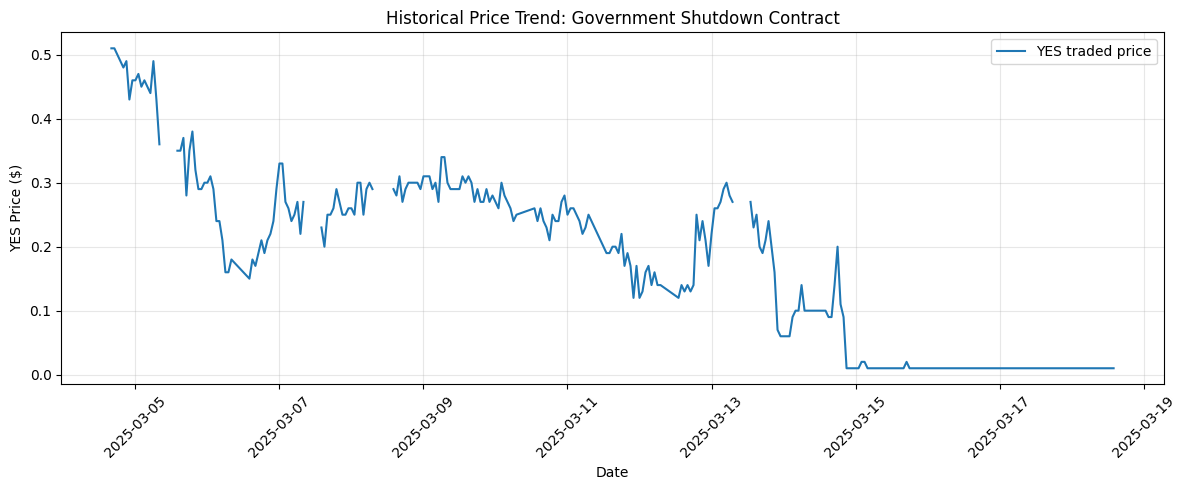

In [12]:
# Convert traded price to numeric
candlesticks_df["trade_price_close"] = pd.to_numeric(
    candlesticks_df["trade_price_close"],
    errors="coerce"
)

plt.figure(figsize=(12, 5))

plt.plot(
    candlesticks_df["timestamp"],
    candlesticks_df["trade_price_close"],
    label="YES traded price"
)

plt.title("Historical Price Trend: Government Shutdown Contract")
plt.xlabel("Date")
plt.ylabel("YES Price ($)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Build Preliminary 2025 Contract Dataset**

##### **Select series from each research category**

In [13]:
# Define four research categories and map Kalshi categories to them

category_map = {
    "Politics": "Politics and Elections",
    "Elections": "Politics and Elections",
    "Financials": "Economics and Financial Markets",
    "Economics": "Economics and Financial Markets",
    "Commodities": "Economics and Financial Markets",
    "Companies": "Companies and Business",
    "Climate and Weather": "Climate and Weather"
}

# Assign each series to one of our four research categories
series_candidates = relevant_series_df.copy()

series_candidates["research_category"] = (
    series_candidates["category"].map(category_map)
)

# Keep only series that belong to the four research categories
series_candidates = series_candidates.dropna(
    subset=["research_category"]
).copy()

# Convert volume to numeric for reliable sorting
series_candidates["volume_numeric"] = pd.to_numeric(
    series_candidates["volume_fp"],
    errors="coerce"
)

# Initially select the 20 highest-volume series per category
series_to_search_df = (
    series_candidates
    .sort_values("volume_numeric", ascending=False)
    .groupby("research_category")
    .head(20)
    .drop_duplicates(subset=["ticker"])
    .copy()
)

print("Series selected for retrieval:", len(series_to_search_df))

display(
    series_to_search_df[[
        "ticker",
        "title",
        "category",
        "research_category",
        "volume_fp"
    ]]
)

Series selected for retrieval: 80


,ticker,title,category,research_category,volume_fp
6572,KXGOLD15M,Gold 15-minute,Commodities,Economics and Financial Markets,1787013941.00
12847,KXFEDDECISION,Fed meeting,Economics,Economics and Financial Markets,637451620.00
11196,PRES,Presidential elections,Elections,Politics and Elections,535948943.00
1332,KXWTI15M,WTI 15-minute,Commodities,Economics and Financial Markets,494259140.00
1830,KXINXU,S&P 500 above/below,Financials,Economics and Financial Markets,369477726.00
...,...,...,...,...,...
10361,KXUALA,United Airlines KPI,Companies,Companies and Business,95003.00
4578,KXCOMPANYLAYOFF,Company Layoffs,Companies,Companies and Business,78279.00
11934,KXOPENAICEO,OpenAI new CEO,Companies,Companies and Business,72692.00
3212,KXEBAYA,Ebay Annual KPI,Companies,Companies and Business,67438.00


##### **Retrieve historical contracts from the selected series**

In [14]:
import time

# Function to retrieve all pages of contracts for one series
def retrieve_series_markets(series_ticker, endpoint):

    all_markets = []
    cursor = None

    while True:

        url = f"{BASE_URL}{endpoint}"

        params = {
            "limit": 1000,
            "series_ticker": series_ticker
        }

        # Exclude multivariate contracts on the live endpoint
        if endpoint == "/markets":
            params["mve_filter"] = "exclude"

        # Add cursor when retrieving subsequent pages
        if cursor:
            params["cursor"] = cursor

        response = requests.get(
            url,
            params=params,
            timeout=30
        )

        # Handle rate limiting
        if response.status_code == 429:
            print("Rate limited. Waiting before retrying...")
            time.sleep(2)
            continue

        response.raise_for_status()

        data = response.json()

        markets = data.get("markets", [])

        all_markets.extend(markets)

        # Check whether another page exists
        cursor = data.get("cursor")

        if not cursor:
            break

        time.sleep(0.2)

    return all_markets

In [15]:
# Retrieve contracts from all selected series

all_candidate_markets = []

for i, row in enumerate(
    series_to_search_df.itertuples(index=False),
    start=1
):

    series_ticker = row.ticker
    research_category = row.research_category

    print(
        f"{i}/{len(series_to_search_df)}: "
        f"Retrieving {series_ticker}"
    )

    # Retrieve archived historical contracts
    historical_markets = retrieve_series_markets(
        series_ticker,
        "/historical/markets"
    )

    # Retrieve contracts still present in the live endpoint
    live_markets = retrieve_series_markets(
        series_ticker,
        "/markets"
    )

    # Combine both sources
    for market in historical_markets:
        market["data_source"] = "historical"
        market["research_category"] = research_category

    for market in live_markets:
        market["data_source"] = "live"
        market["research_category"] = research_category

    all_candidate_markets.extend(historical_markets)
    all_candidate_markets.extend(live_markets)

    time.sleep(0.2)

# Convert to DataFrame
candidate_contracts_df = pd.DataFrame(
    all_candidate_markets
)

print(
    "Total contracts retrieved:",
    len(candidate_contracts_df)
)

1/80: Retrieving KXGOLD15M
2/80: Retrieving KXFEDDECISION
3/80: Retrieving PRES
4/80: Retrieving KXWTI15M
5/80: Retrieving KXINXU
6/80: Retrieving KXSILVER15M
7/80: Retrieving KXPRESNOMD
8/80: Retrieving KXFEDCHAIRNOM
9/80: Retrieving CONTROLH
10/80: Retrieving KXNASDAQ100U
11/80: Retrieving SENATETX
12/80: Retrieving KXHIGHLAX
13/80: Retrieving KXBALANCEPOWERCOMBO
14/80: Retrieving KXHIGHNY
15/80: Retrieving KXMAYORLA
16/80: Retrieving KXINX
17/80: Retrieving POPVOTEMOV
18/80: Retrieving KXMAYORNYCPARTY
19/80: Retrieving KXGOVSHUTLENGTH
20/80: Retrieving CONTROLS
21/80: Retrieving KXHIGHCHI
22/80: Retrieving KXWTI
23/80: Retrieving KXNASDAQ100
24/80: Retrieving KXHIGHMIA
25/80: Retrieving GOVPARTYTX
26/80: Retrieving KXNATGAS15M
27/80: Retrieving KXPRESPERSON
28/80: Retrieving KXPRESNOMR
29/80: Retrieving ECMOV
30/80: Retrieving POPVOTEMOVSMALL
31/80: Retrieving KXRAIN
32/80: Retrieving KXCOPPER15M
33/80: Retrieving SENATEMI
34/80: Retrieving POPVOTE
35/80: Retrieving KXHIGHAUS
36/80:

##### **Clean candidate contracts**

In [16]:
# Remove duplicate contracts
candidate_contracts_df = (
    candidate_contracts_df
    .drop_duplicates(subset=["ticker"])
    .copy()
)

# Remove multivariate contracts
if "mve_collection_ticker" in candidate_contracts_df.columns:

    candidate_contracts_df = candidate_contracts_df[
        candidate_contracts_df["mve_collection_ticker"].isna()
    ].copy()

print(
    "Individual contracts after removing duplicates and MVEs:",
    len(candidate_contracts_df)
)

Individual contracts after removing duplicates and MVEs: 2096476


##### **Filter for contracts that were active during 2025**

In [17]:
# Define our study period in UTC
study_start = pd.Timestamp("2025-01-01", tz="UTC")
study_end = pd.Timestamp("2026-01-01", tz="UTC")

# Convert date columns to datetime
candidate_contracts_df["created_time"] = pd.to_datetime(
    candidate_contracts_df["created_time"],
    utc=True,
    errors="coerce"
)

candidate_contracts_df["close_time"] = pd.to_datetime(
    candidate_contracts_df["close_time"],
    utc=True,
    errors="coerce"
)

candidate_contracts_df["settlement_ts"] = pd.to_datetime(
    candidate_contracts_df["settlement_ts"],
    utc=True,
    errors="coerce"
)

# Use close_time to identify when trading ended.
# If unavailable, use settlement_ts as a fallback.
candidate_contracts_df["effective_end_time"] = (
    candidate_contracts_df["close_time"]
    .fillna(candidate_contracts_df["settlement_ts"])
)

# A contract must have opened by the end of 2025
# and remained active at least until some point in 2025.
active_2025 = (
    (candidate_contracts_df["created_time"] < study_end) &
    (candidate_contracts_df["effective_end_time"] >= study_start)
)

contracts_2025_df = candidate_contracts_df[
    active_2025
].copy()

# Calculate duration in days
contracts_2025_df["duration_days"] = (
    contracts_2025_df["effective_end_time"] -
    contracts_2025_df["created_time"]
).dt.total_seconds() / (60 * 60 * 24)

# Convert volume to numeric
contracts_2025_df["volume_numeric"] = pd.to_numeric(
    contracts_2025_df["volume_fp"],
    errors="coerce"
)

print("Contracts active during 2025:", len(contracts_2025_df))

display(
    contracts_2025_df[[
        "ticker",
        "title",
        "research_category",
        "created_time",
        "effective_end_time",
        "duration_days",
        "volume_numeric",
        "result"
    ]].head(20)
)

Contracts active during 2025: 1021638


,ticker,title,research_category,created_time,effective_end_time,duration_days,volume_numeric,result
7442,KXFEDDECISION-26JUL-H26,Will the Federal Reserve Hike rates by >25bps ...,Economics and Financial Markets,2025-09-26 15:30:54.586444+00:00,2026-07-29 17:59:00+00:00,306.102840,15632302.75,no
7443,KXFEDDECISION-26JUL-H25,Will the Federal Reserve Hike rates by 25bps a...,Economics and Financial Markets,2025-09-26 15:30:54.586444+00:00,2026-07-29 17:59:00+00:00,306.102840,19713687.51,no
7444,KXFEDDECISION-26JUL-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,2025-09-26 15:30:54.586444+00:00,2026-07-29 17:59:00+00:00,306.102840,23802367.03,yes
7445,KXFEDDECISION-26JUL-C26,Will the Federal Reserve Cut rates by >25bps a...,Economics and Financial Markets,2025-09-26 15:30:54.586444+00:00,2026-07-29 17:59:00+00:00,306.102840,2330631.58,no
7446,KXFEDDECISION-26JUL-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets,2025-09-26 15:30:54.586444+00:00,2026-07-29 17:59:00+00:00,306.102840,7276758.07,no
7447,KXFEDDECISION-26JUN-H26,Will the Federal Reserve Hike rates by >25bps ...,Economics and Financial Markets,2025-09-26 15:30:48.077821+00:00,2026-06-17 17:59:00+00:00,264.102916,1608414.91,no
7448,KXFEDDECISION-26JUN-H25,Will the Federal Reserve Hike rates by 25bps a...,Economics and Financial Markets,2025-09-26 15:30:48.077821+00:00,2026-06-17 17:59:00+00:00,264.102916,6471952.48,no
7449,KXFEDDECISION-26JUN-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,2025-09-26 15:30:48.077821+00:00,2026-06-17 17:59:00+00:00,264.102916,11917184.36,yes
7450,KXFEDDECISION-26JUN-C26,Will the Federal Reserve Cut rates by >25bps a...,Economics and Financial Markets,2025-09-26 15:30:48.077821+00:00,2026-06-17 17:59:00+00:00,264.102916,3382986.13,no
7451,KXFEDDECISION-26JUN-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets,2025-09-26 15:30:48.077821+00:00,2026-06-17 17:59:00+00:00,264.102916,9796684.97,no


##### **Inspect candidate pool categories**

In [18]:
# Count contracts by research category

category_summary = (
    contracts_2025_df
    .groupby("research_category")
    .agg(
        contract_count=("ticker", "nunique"),
        median_volume=("volume_numeric", "median"),
        median_duration_days=("duration_days", "median")
    )
    .reset_index()
)

display(category_summary)

,research_category,contract_count,median_volume,median_duration_days
0,Climate and Weather,15860,7504.00,1.810714
1,Companies and Business,26,316756.00,165.305557
2,Economics and Financial Markets,1005448,0.00,1.498355
3,Politics and Elections,304,2544401.46,228.180397


In [19]:
# Examine trading volume distribution

display(
    contracts_2025_df["volume_numeric"].describe()
)

count    1.021638e+06
mean     3.959015e+03
std      5.147044e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.733129e+08
Name: volume_numeric, dtype: float64

##### **Prepare contract screening variables**

In [20]:
# Create a copy of the 2025 candidate dataset
screening_df = contracts_2025_df.copy()

# Calculate the portion of each contract's lifetime
# that overlaps with our 2025 observation period

screening_df["overlap_start"] = screening_df["created_time"].clip(
    lower=study_start
)

screening_df["overlap_end"] = screening_df["effective_end_time"].clip(
    upper=study_end
)

screening_df["days_active_2025"] = (
    screening_df["overlap_end"] -
    screening_df["overlap_start"]
).dt.total_seconds() / 86400

# Ensure volume is numeric
screening_df["volume_numeric"] = pd.to_numeric(
    screening_df["volume_fp"],
    errors="coerce"
)

# Inspect the results
display(
    screening_df[[
        "ticker",
        "title",
        "research_category",
        "days_active_2025",
        "duration_days",
        "volume_numeric"
    ]].head(20)
)

,ticker,title,research_category,days_active_2025,duration_days,volume_numeric
7442,KXFEDDECISION-26JUL-H26,Will the Federal Reserve Hike rates by >25bps ...,Economics and Financial Markets,96.353535,306.102840,15632302.75
7443,KXFEDDECISION-26JUL-H25,Will the Federal Reserve Hike rates by 25bps a...,Economics and Financial Markets,96.353535,306.102840,19713687.51
7444,KXFEDDECISION-26JUL-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,96.353535,306.102840,23802367.03
7445,KXFEDDECISION-26JUL-C26,Will the Federal Reserve Cut rates by >25bps a...,Economics and Financial Markets,96.353535,306.102840,2330631.58
7446,KXFEDDECISION-26JUL-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets,96.353535,306.102840,7276758.07
7447,KXFEDDECISION-26JUN-H26,Will the Federal Reserve Hike rates by >25bps ...,Economics and Financial Markets,96.353610,264.102916,1608414.91
7448,KXFEDDECISION-26JUN-H25,Will the Federal Reserve Hike rates by 25bps a...,Economics and Financial Markets,96.353610,264.102916,6471952.48
7449,KXFEDDECISION-26JUN-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,96.353610,264.102916,11917184.36
7450,KXFEDDECISION-26JUN-C26,Will the Federal Reserve Cut rates by >25bps a...,Economics and Financial Markets,96.353610,264.102916,3382986.13
7451,KXFEDDECISION-26JUN-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets,96.353610,264.102916,9796684.97


##### **Examine potential screening thresholds**

In [21]:
# Test different minimum trading volumes
volume_thresholds = [100, 500, 1000, 5000]

screening_results = []

for threshold in volume_thresholds:

    eligible = screening_df[
        (screening_df["days_active_2025"] >= 1) &
        (screening_df["volume_numeric"] >= threshold)
    ]

    counts = eligible.groupby(
        "research_category"
    )["ticker"].nunique()

    for category in [
        "Politics and Elections",
        "Economics and Financial Markets",
        "Companies and Business",
        "Climate and Weather"
    ]:

        screening_results.append({
            "Minimum Volume": threshold,
            "Category": category,
            "Eligible Contracts": counts.get(category, 0)
        })

threshold_summary = pd.DataFrame(screening_results)

display(
    threshold_summary.pivot(
        index="Minimum Volume",
        columns="Category",
        values="Eligible Contracts"
    )
)

Category,Climate and Weather,Companies and Business,Economics and Financial Markets,Politics and Elections
Minimum Volume,,,,
100,14964,23,35529,302
500,13850,23,24927,302
1000,13077,23,20211,302
5000,9498,23,8539,301


##### **Select preliminary 40 contracts**

In [22]:
# Initial screening criteria
MIN_VOLUME = 100
MIN_DURATION_DAYS = 1

eligible_contracts_df = screening_df[
    (screening_df["days_active_2025"] >= MIN_DURATION_DAYS) &
    (screening_df["volume_numeric"] >= MIN_VOLUME)
].copy()

# Sort by volume within each category
eligible_contracts_df = eligible_contracts_df.sort_values(
    "volume_numeric",
    ascending=False
)

# Select up to 10 contracts per category
# Prefer different events to increase sample diversity

pilot_contracts = []

categories = [
    "Politics and Elections",
    "Economics and Financial Markets",
    "Companies and Business",
    "Climate and Weather"
]

for category in categories:

    category_df = eligible_contracts_df[
        eligible_contracts_df["research_category"] == category
    ].copy()

    # Prefer one contract per event
    category_df = category_df.drop_duplicates(
        subset=["event_ticker"]
    )

    selected = category_df.head(10)

    pilot_contracts.append(selected)

# Combine selected contracts
pilot_contracts_df = pd.concat(
    pilot_contracts,
    ignore_index=True
)

print("Total pilot contracts:", len(pilot_contracts_df))

display(
    pilot_contracts_df[[
        "ticker",
        "event_ticker",
        "title",
        "research_category",
        "volume_numeric",
        "days_active_2025"
    ]]
)

Total pilot contracts: 40


,ticker,event_ticker,title,research_category,volume_numeric,days_active_2025
0,PRES-2024-KH,PRES-2024,Will Kamala Harris or another Democrat win the...,Politics and Elections,2.733129e+08,19.752851
1,CONTROLH-2026-R,CONTROLH-2026,Will Republicans win the House in 2026?,Politics and Elections,1.581942e+08,365.000000
2,SENATETX-26-R,SENATETX-26,Will Republicans win the Senate race in Texas?,Politics and Elections,1.411665e+08,365.000000
3,KXFEDCHAIRNOM-29-JS,KXFEDCHAIRNOM-29,Will Trump next nominate Judy Shelton as Fed C...,Politics and Elections,1.153597e+08,365.000000
4,GOVPARTYTX-26-R,GOVPARTYTX-26,Will the Republican party win the governorship...,Politics and Elections,8.528574e+07,340.118038
5,CONTROLS-2026-R,CONTROLS-2026,Will Republicans win the U.S. Senate in 2026?,Politics and Elections,8.298170e+07,365.000000
6,SENATEMI-26-R,SENATEMI-26,Will Republicans win the Senate race in Michigan?,Politics and Elections,6.038959e+07,365.000000
7,KXBALANCEPOWERCOMBO-27FEB-RR,KXBALANCEPOWERCOMBO-27FEB,Will House Control be Republican AND Senate Co...,Politics and Elections,6.028343e+07,21.137397
8,KXMAYORNYCPARTY-25-AC,KXMAYORNYCPARTY-25,Will a representative of the Andrew Cuomo part...,Politics and Elections,5.342315e+07,134.985762
9,KXMAYORLA-26-KBAS,KXMAYORLA-26,Who will win Los Angeles Mayoral Election?,Politics and Elections,5.191341e+07,175.940952


##### **Check category distribution**

In [23]:
pilot_summary = (
    pilot_contracts_df
    .groupby("research_category")
    .agg(
        contracts=("ticker", "nunique"),
        median_volume=("volume_numeric", "median"),
        median_active_days=("days_active_2025", "median")
    )
    .reset_index()
)

display(pilot_summary)

,research_category,contracts,median_volume,median_active_days
0,Climate and Weather,10,4.917780e+05,1.811327
1,Companies and Business,10,1.435530e+05,129.734773
2,Economics and Financial Markets,10,1.810317e+07,94.702568
3,Politics and Elections,10,8.413372e+07,352.559019


##### **Save preliminary contract dataset**

In [24]:
# Save preliminary pilot contract dataset

pilot_contracts_df.to_csv(
    "kalshi_pilot_40_contracts.csv",
    index=False
)

print("Pilot contract dataset saved successfully.")

Pilot contract dataset saved successfully.


##### **Revise contract list**

In [25]:
from kalshi_revised_sample import check_category_supply, select_revised_sample, compare_samples

check_category_supply(screening_df)
revised_df = select_revised_sample(screening_df)
compare_samples("kalshi_pilot_40_contracts.csv", revised_df)

Eligible supply under the revised filters:


,eligible_contracts,distinct_events,distinct_series
research_category,,,
Politics and Elections,125,12,11
Economics and Financial Markets,531,64,8
Companies and Business,20,8,8
Climate and Weather,0,0,0



Climate series that survive the filters:
  none
Note: Companies and Business has only 8 eligible contracts.
Note: Climate and Weather has only 0 eligible contracts.

Revised sample size: 28


,contracts,series,median_volume,median_days_2025
research_category,,,,
Companies and Business,8,8,1.435530e+05,136.317989
Economics and Financial Markets,10,7,3.012323e+06,137.071796
Politics and Elections,10,10,7.168565e+07,357.140828


,ticker,title,research_category,series_ticker,days_active_2025,share_in_2025,volume_numeric,result
0,KXSUPERBOWLAD-SB2026-ANTHROPIC,Will Anthropic run an ad during the Big Game 2...,Companies and Business,KXSUPERBOWLAD,128.084289,0.765803,3.299523e+07,no
1,KXMUSKPACKAGEVOTE-26JAN01,Will Tesla shareholders approve Elon Musk's ne...,Companies and Business,KXMUSKPACKAGEVOTE,62.191566,1.000000,1.594577e+06,yes
2,KXOAIPROFIT-26-JAN01,Will OpenAI end its not-for-profit status befo...,Companies and Business,KXOAIPROFIT,300.692692,0.840764,1.967990e+05,yes
3,KXLEAVECRACKERBARREL-26JAN,Julie Felss Masino out as Cracker Barrel CEO b...,Companies and Business,KXLEAVECRACKERBARREL,131.385258,0.998422,1.494090e+05,no
4,KXRENAMECOMMANDERS-25,Will the Washington Commanders be renamed to t...,Companies and Business,KXRENAMECOMMANDERS,163.313573,0.998730,1.376970e+05,no
5,KXAAPLPRICE17OVER16-25-799.01,What will be the price of iPhone 17?,Companies and Business,KXAAPLPRICE17OVER16,48.723337,1.000000,1.259470e+05,no
6,KXAAPLPRICEFOLD-27-2000,What will be the price of a foldable iPhone?,Companies and Business,KXAAPLPRICEFOLD,167.235896,0.399123,1.108926e+05,no
7,KXELONSUEAPPLE-26,Will Elon Musk sue Apple before 2026?,Companies and Business,KXELONSUEAPPLE,141.250721,0.997034,6.357200e+04,no
8,KXFEDDECISION-26SEP-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,KXFEDDECISION,96.353481,0.271340,4.828612e+07,no
9,KXFEDDECISION-25SEP-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,KXFEDDECISION,63.083067,1.000000,4.271886e+07,no


Saved to kalshi_pilot_revised_contracts.csv
Kept: 18  Dropped: 22  Added: 10

Dropped:


,ticker,title,research_category
0,PRES-2024-KH,Will Kamala Harris or another Democrat win the...,Politics and Elections
7,KXBALANCEPOWERCOMBO-27FEB-RR,Will House Control be Republican AND Senate Co...,Politics and Elections
12,KXFEDDECISION-26JUL-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets
13,KXFEDDECISION-25JUL-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets
14,KXFEDDECISION-26JAN-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets
15,KXFEDDECISION-25MAY-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets
16,KXFEDDECISION-25JUN-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets
17,KXFEDDECISION-25DEC-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets
18,KXFEDDECISION-25OCT-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets
19,KXFEDDECISION-26MAR-C25,Will the Federal Reserve Cut rates by 25bps at...,Economics and Financial Markets



Added:


,ticker,title,research_category
10,KXRATECUTCOUNT-25DEC31-T3,Will the Fed cut rates 3 times?,Economics and Financial Markets
11,FED-25MAY-T4.25,Will the upper bound of the federal funds rate...,Economics and Financial Markets
12,KXFED-26APR-T3.75,Will the upper bound of the federal funds rate...,Economics and Financial Markets
13,KXINXY-25DEC31-B7100,Will the S&P 500 be between 7000 and 7199.99 a...,Economics and Financial Markets
14,KXFED-26JUN-T3.75,Will the upper bound of the federal funds rate...,Economics and Financial Markets
15,KXCPIYOY-25APR-T2.5,Will the rate of CPI inflation be above 2.5% f...,Economics and Financial Markets
16,FED-25SEP-T4.25,Will the upper bound of the federal funds rate...,Economics and Financial Markets
17,KXAAAGASM-25JUN30-3.30,Will average **gas prices** be above $3.30?,Economics and Financial Markets
26,KXGOVCA-26-SHIL,Who will win the governorship in California?,Politics and Elections
27,KXGOVFLNOMR-26-BD,Will Byron Donalds be the Republican nominee f...,Politics and Elections


(    can_close_early                 close_time  \
 0              True                        NaN   
 7              True  2026-11-04 05:03:42+00:00   
 12             True  2026-07-29 17:59:00+00:00   
 13             True  2025-07-30 17:55:00+00:00   
 14             True  2026-01-28 18:59:00+00:00   
 15             True  2025-05-07 17:55:00+00:00   
 16             True  2025-06-18 17:55:00+00:00   
 17             True  2025-12-10 18:59:00+00:00   
 18             True  2025-10-29 17:59:00+00:00   
 19             True  2026-03-18 17:59:00+00:00   
 21             True                        NaN   
 28             True                        NaN   
 30             True  2025-12-23 07:59:00+00:00   
 31             True  2025-12-30 05:59:00+00:00   
 32             True  2025-11-10 05:59:00+00:00   
 33             True  2025-12-06 07:59:00+00:00   
 34             True  2025-10-14 03:59:00+00:00   
 35             True  2025-12-14 05:59:00+00:00   
 36             True  2025-12-1

##### **Pull hourly candlesticks for each contract**

1/28: KXSUPERBOWLAD-SB2026-ANTHROPIC
2/28: KXMUSKPACKAGEVOTE-26JAN01
3/28: KXOAIPROFIT-26-JAN01
4/28: KXLEAVECRACKERBARREL-26JAN
5/28: KXRENAMECOMMANDERS-25
6/28: KXAAPLPRICE17OVER16-25-799.01
7/28: KXAAPLPRICEFOLD-27-2000
8/28: KXELONSUEAPPLE-26
9/28: KXFEDDECISION-26SEP-H0
10/28: KXFEDDECISION-25SEP-H0
11/28: KXRATECUTCOUNT-25DEC31-T3
12/28: FED-25MAY-T4.25
13/28: KXFED-26APR-T3.75
14/28: KXINXY-25DEC31-B7100
15/28: KXFED-26JUN-T3.75
16/28: KXCPIYOY-25APR-T2.5
17/28: FED-25SEP-T4.25
18/28: KXAAAGASM-25JUN30-3.30
19/28: CONTROLH-2026-R
20/28: SENATETX-26-R
21/28: KXFEDCHAIRNOM-29-JS
22/28: GOVPARTYTX-26-R
23/28: CONTROLS-2026-R
24/28: SENATEMI-26-R
25/28: KXMAYORNYCPARTY-25-AC
26/28: KXMAYORLA-26-KBAS
27/28: KXGOVCA-26-SHIL
28/28: KXGOVFLNOMR-26-BD

Price histories saved for 28 of 28 contracts in /Users/rc/Documents/Stevens/Fall 2026/CS 584/Project/Code/data/pilot


,ticker,title,research_category,result,hours,pct_hours_traded,median_spread,first_mid,last_mid,min_mid,max_mid,moves_over_5c
0,KXSUPERBOWLAD-SB2026-ANTHROPIC,Will Anthropic run an ad during the Big Game 2...,Companies and Business,no,3072,6.9,0.05,0.100,0.645,0.100,0.660,7
1,KXMUSKPACKAGEVOTE-26JAN01,Will Tesla shareholders approve Elon Musk's ne...,Companies and Business,yes,1492,20.4,0.04,0.900,0.995,0.520,0.995,8
2,KXOAIPROFIT-26-JAN01,Will OpenAI end its not-for-profit status befo...,Companies and Business,yes,7209,8.9,0.04,0.890,0.970,0.160,0.975,52
3,KXLEAVECRACKERBARREL-26JAN,Julie Felss Masino out as Cracker Barrel CEO b...,Companies and Business,no,3154,15.3,0.01,0.165,0.010,0.005,0.590,7
4,KXRENAMECOMMANDERS-25,Will the Washington Commanders be renamed to t...,Companies and Business,no,3920,13.4,0.01,0.080,0.005,0.005,0.115,0
5,KXAAPLPRICE17OVER16-25-799.01,What will be the price of iPhone 17?,Companies and Business,no,1169,50.4,0.05,0.360,0.005,0.005,0.780,29
6,KXAAPLPRICEFOLD-27-2000,What will be the price of a foldable iPhone?,Companies and Business,no,3994,1.5,0.08,0.360,0.755,0.360,0.870,6
7,KXELONSUEAPPLE-26,Will Elon Musk sue Apple before 2026?,Companies and Business,no,3389,5.0,0.05,0.155,0.005,0.005,0.655,22
8,KXFEDDECISION-26SEP-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,no,2240,0.0,0.08,0.495,0.700,0.495,0.700,7
9,KXFEDDECISION-25SEP-H0,Will the Federal Reserve Hike rates by 0bps at...,Economics and Financial Markets,no,1179,90.8,0.01,0.315,0.025,0.015,0.605,8


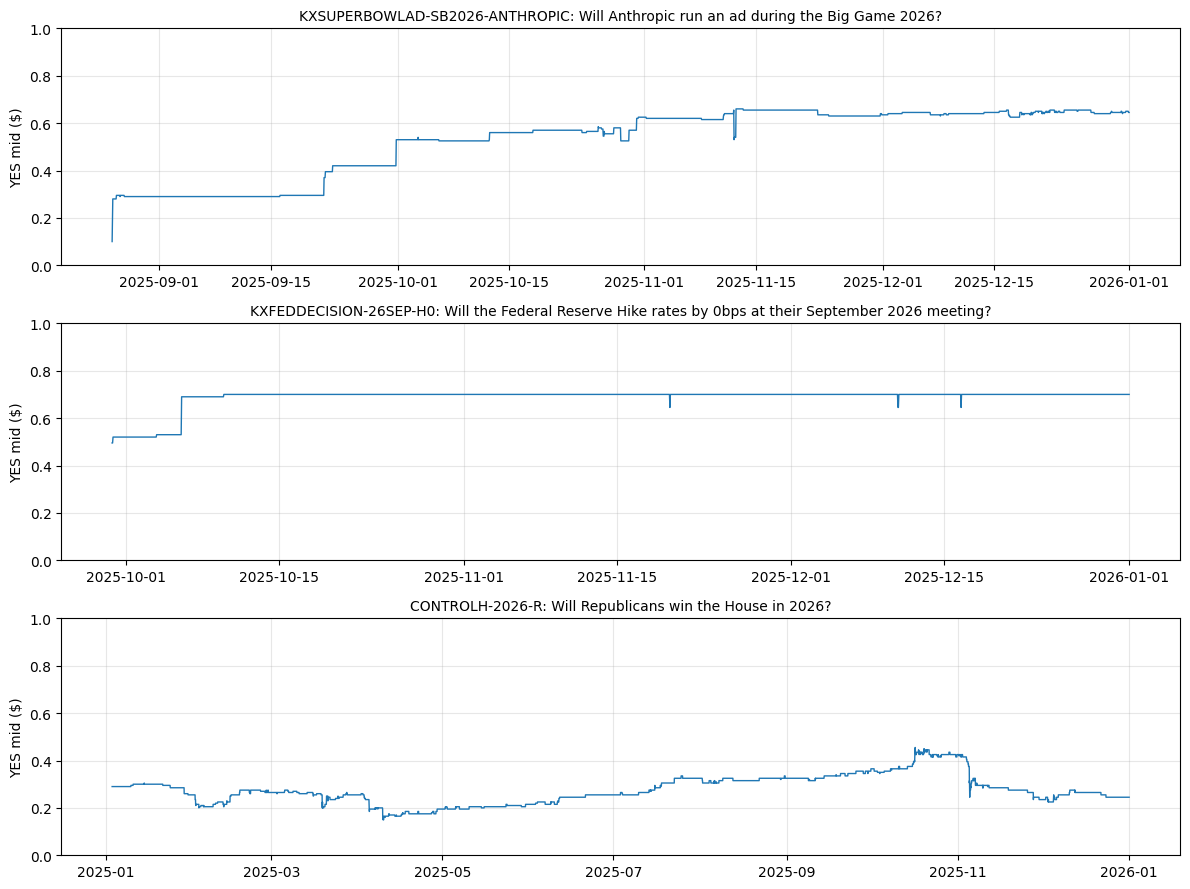

In [26]:
from kalshi_price_history import collect_price_histories, plot_contracts

prices_df, price_summary_df = collect_price_histories(revised_df)
display(price_summary_df)
plot_contracts(prices_df, revised_df, n=3)

### **Collect news articles**

##### **Test run on 2 contracts**

In [26]:
from kalshi_gdelt_news import CONTRACT_QUERIES, collect_articles

test_articles, test_summary = collect_articles(
    revised_df, tickers=["KXOAIPROFIT-26-JAN01", "KXAAAGASM-25JUN30-3.30"]
)
display(test_summary)
display(test_articles[["ticker", "published", "domain", "title"]].head(20))

1/2: KXOAIPROFIT-26-JAN01 (43 windows)
2/2: KXAAAGASM-25JUN30-3.30 (6 windows)

Saved 2898 articles to /Users/rc/Documents/Stevens/Fall 2026/CS 584/Project/Code/data/pilot


,ticker,windows,windows_capped_at_250,articles,unique_stories,first_article,last_article
0,KXOAIPROFIT-26-JAN01,43,2,2433,1327,2025-01-22 00:00:00+00:00,2025-10-21 21:30:00+00:00
1,KXAAAGASM-25JUN30-3.30,6,1,465,272,2025-05-22 00:15:00+00:00,2025-06-14 17:00:00+00:00


,ticker,published,domain,title
0,KXAAAGASM-25JUN30-3.30,2025-05-22 00:15:00+00:00,insidehalton.com,Circle K to drop gas prices by 10 / cents a li...
1,KXAAAGASM-25JUN30-3.30,2025-05-22 00:30:00+00:00,redstate.com,An Energy Renaissance in the Making - Trump En...
2,KXAAAGASM-25JUN30-3.30,2025-05-22 01:00:00+00:00,orangeville.com,Circle K to drop gas prices by 10 / cents a li...
3,KXAAAGASM-25JUN30-3.30,2025-05-22 01:00:00+00:00,yahoo.com,Travelers talk vacation ahead of Memorial Day
4,KXAAAGASM-25JUN30-3.30,2025-05-22 01:00:00+00:00,yahoo.com,Memorial Day weekend travel : What to expect
5,KXAAAGASM-25JUN30-3.30,2025-05-22 01:00:00+00:00,yahoo.com,Study : Expanding Renewable Energy Does Not Lo...
6,KXAAAGASM-25JUN30-3.30,2025-05-22 01:00:00+00:00,ktvu.com,Lawmakers weigh ending EV tax credits in Trump...
7,KXAAAGASM-25JUN30-3.30,2025-05-22 02:15:00+00:00,oilprice.com,Study : Expanding Renewable Energy Does Not Lo...
8,KXAAAGASM-25JUN30-3.30,2025-05-22 03:00:00+00:00,krdo.com,"Circle K offering Memorial Day gas discounts ,..."
9,KXAAAGASM-25JUN30-3.30,2025-05-22 03:15:00+00:00,durhamregion.com,Circle K to drop gas prices by 10 / cents a li...


##### **Full pipeline on entire collection of contracts**

In [ ]:
from kalshi_gdelt_bigquery import estimate_cost, collect_articles_bq

PROJECT = "kalshi-market-predictor"  
estimate_cost(revised_df, PROJECT)

/Users/rc/Library/Python/3.12/lib/python/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


Query would scan 77 GB (8% of the 1 TB monthly free tier).


77.201719309

In [31]:
articles_df, news_summary_df = collect_articles_bq(revised_df, PROJECT)
display(news_summary_df)

No terms defined, skipping: GOVPARTYTX-26-R, KXFED-26APR-T3.75, KXFED-26JUN-T3.75, KXFEDDECISION-26SEP-H0, KXMAYORNYCPARTY-25-AC, KXRENAMECOMMANDERS-25


/Users/rc/Library/Python/3.12/lib/python/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


Running BigQuery scan (usually 1 to 5 minutes)...


/Users/rc/Library/Python/3.12/lib/python/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Saved 714,433 headline matches to data/pilot/gkg_headline_matches_2025.csv
Saved 246,041 articles for 21 contracts to /Users/rc/Documents/Stevens/Fall 2026/CS 584/Project/Code/data/pilot


,ticker,articles,unique_stories,first_article,last_article
0,KXSUPERBOWLAD-SB2026-ANTHROPIC,0,0,NaT,NaT
1,KXMUSKPACKAGEVOTE-26JAN01,971,436,2025-09-05 18:15:00+00:00,2025-11-06 22:30:00+00:00
2,KXOAIPROFIT-26-JAN01,1133,490,2025-01-01 17:15:00+00:00,2025-10-28 16:30:00+00:00
3,KXLEAVECRACKERBARREL-26JAN,5817,1458,2025-08-22 15:00:00+00:00,2025-12-29 16:45:00+00:00
4,KXAAPLPRICE17OVER16-25-799.01,667,522,2025-07-24 04:45:00+00:00,2025-09-10 15:30:00+00:00
5,KXAAPLPRICEFOLD-27-2000,691,651,2025-07-17 22:30:00+00:00,2025-12-31 22:30:00+00:00
6,KXELONSUEAPPLE-26,530,212,2025-08-12 18:00:00+00:00,2025-12-14 05:30:00+00:00
7,KXFEDDECISION-25SEP-H0,7727,3391,2025-07-16 16:15:00+00:00,2025-09-17 17:45:00+00:00
8,KXRATECUTCOUNT-25DEC31-T3,28312,12881,2025-01-01 13:00:00+00:00,2026-01-01 00:00:00+00:00
9,FED-25MAY-T4.25,7648,3173,2025-01-01 13:00:00+00:00,2025-05-07 17:30:00+00:00


##### **Filtering out contracts for modeling**

In [37]:
from kalshi_gdelt_bigquery import CONTRACT_TERMS, collect_articles_bq

# Contracts excluded from modeling
DROPPED = [
    "KXFEDDECISION-26SEP-H0", "KXFED-26APR-T3.75", "KXFED-26JUN-T3.75",   # almost no trading
    "KXRENAMECOMMANDERS-25", "KXMAYORNYCPARTY-25-AC", "GOVPARTYTX-26-R",  # almost no movement
    "KXSUPERBOWLAD-SB2026-ANTHROPIC",                                     # no matching 2025 news
]
model_df = revised_df[~revised_df["ticker"].isin(DROPPED)].reset_index(drop=True)
model_df.to_csv("kalshi_model_contracts.csv", index=False)

# S&P 500: match the index by name only, not general market coverage
terms = dict(CONTRACT_TERMS)
terms["KXINXY-25DEC31-B7100"] = [["s&p 500", "s&p500"]]

articles_df, news_summary_df = collect_articles_bq(model_df, PROJECT, terms=terms)
display(news_summary_df)
print(len(model_df), "contracts in the modeling set")

Using saved matches in data/pilot/gkg_headline_matches_2025.csv
Saved 149,381 articles for 21 contracts to /Users/rc/Documents/Stevens/Fall 2026/CS 584/Project/Code/data/pilot


,ticker,articles,unique_stories,first_article,last_article
0,KXMUSKPACKAGEVOTE-26JAN01,971,436,2025-09-05 18:15:00+00:00,2025-11-06 22:30:00+00:00
1,KXOAIPROFIT-26-JAN01,1133,490,2025-01-01 17:15:00+00:00,2025-10-28 16:30:00+00:00
2,KXLEAVECRACKERBARREL-26JAN,5817,1458,2025-08-22 15:00:00+00:00,2025-12-29 16:45:00+00:00
3,KXAAPLPRICE17OVER16-25-799.01,667,522,2025-07-24 04:45:00+00:00,2025-09-10 15:30:00+00:00
4,KXAAPLPRICEFOLD-27-2000,691,651,2025-07-17 22:30:00+00:00,2025-12-31 22:30:00+00:00
5,KXELONSUEAPPLE-26,530,212,2025-08-12 18:00:00+00:00,2025-12-14 05:30:00+00:00
6,KXFEDDECISION-25SEP-H0,7727,3391,2025-07-16 16:15:00+00:00,2025-09-17 17:45:00+00:00
7,KXRATECUTCOUNT-25DEC31-T3,28312,12881,2025-01-01 13:00:00+00:00,2026-01-01 00:00:00+00:00
8,FED-25MAY-T4.25,7648,3173,2025-01-01 13:00:00+00:00,2025-05-07 17:30:00+00:00
9,KXINXY-25DEC31-B7100,22853,17699,2025-01-01 00:00:00+00:00,2025-12-31 14:15:00+00:00


21 contracts in the modeling set


##### **Sentence-transformer relevance filter and sentiment scoring**

In [39]:
articles_df = pd.read_csv("data/pilot/pilot_articles.csv", parse_dates=["published"])
print(articles_df["ticker"].nunique(), "contracts,", len(articles_df), "articles")

from kalshi_news_scoring import (
    score_relevance, show_relevance_examples, score_sentiment, export_annotation_sample
)

scored_df = score_relevance(articles_df, model_df)
show_relevance_examples(scored_df, "KXMAYORLA-26-KBAS")
scored_df = score_sentiment(scored_df)
annotation_df = export_annotation_sample(scored_df, model_df)

21 contracts, 149381 articles


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/457 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Relevance threshold 0.35: 108864 of 149381 articles kept


,ticker,articles,relevant,median_relevance,pct_relevant
0,CONTROLH-2026-R,19965,8787,0.337643,44.0
1,CONTROLS-2026-R,7333,4599,0.376538,62.7
2,FED-25MAY-T4.25,7648,6533,0.419889,85.4
3,FED-25SEP-T4.25,17624,14826,0.420291,84.1
4,KXAAAGASM-25JUN30-3.30,818,748,0.468900,91.4
5,KXAAPLPRICE17OVER16-25-799.01,667,667,0.671570,100.0
6,KXAAPLPRICEFOLD-27-2000,691,689,0.523817,99.7
7,KXCPIYOY-25APR-T2.5,12091,10319,0.449095,85.3
8,KXELONSUEAPPLE-26,530,529,0.615912,99.8
9,KXFEDCHAIRNOM-29-JS,5835,4281,0.392517,73.4


... (3 outputs left out)

,relevance,headline
113980,0.234271,LA Mayor's Comments Saying ICE Agents Commit '...
113823,0.223662,LA mayor signs executive order supporting immi...
114210,0.216596,LA mayor calls for Congressional investigation...
114031,0.215482,"Booker T. Washington Warned Us: Curren Price, ..."
113817,0.199447,ICE Rescues Children At Marijuana Farm – LA Ma...
114317,0.199144,LA mayor condemns protest outside synagogue ev...
113860,0.179090,Los Angeles mayor celebrates 'retreat' as Pent...
114305,0.163577,Master Lock Partners with Los Angeles Mayor's ...


Around the threshold:


,relevance,headline
114050,0.355028,Karen Bass 'Dissents' With Supreme Court ICE R...
113879,0.350962,LA Mayor Bass Decries ICE — No 'Right' to Be M...
113859,0.350017,LA mayor throws a tantrum | LETTER | Letters
114023,0.348238,Karen Bass Says 'Grants For Violence Preventio...
113903,0.346975,Karen Bass' Bizarre Take About Fruit Sellers a...
114368,0.344521,LA Mayor Erupts Into Racist Tirade Against His...
114355,0.344498,Karen Bass's Weepy Post About How SCARED Poor ...
114093,0.342315,LA mayor makes first OKC visit as cities partn...


58428 headlines reuse saved scores, 0 new headlines to score
Saved data/pilot/pilot_articles_scored.csv
Saved 252 rows for annotation to data/pilot/stance_annotation_sample.csv


### **Building the modeling dataset**

In [40]:
import pandas as pd
model_df = pd.read_csv("kalshi_model_contracts.csv")
prices_df = pd.read_csv("data/pilot/pilot_prices_hourly_2025.csv")
scored_df = pd.read_csv("data/pilot/pilot_articles_scored.csv")

##### **Tracking price change with news sentiment**

In [41]:
from kalshi_model_dataset import build_dataset, association_table

dataset = build_dataset(prices_df, scored_df, model_df)
display(association_table(dataset))

Saved 551,430 rows to data/pilot/model_dataset.csv
21 contracts, 18,410 checkpoints per (w, h) pair, 6 lookbacks x 5 horizons
Share of checkpoints with relevant news in the window:


,has_news
lookback_h,
1,0.196
3,0.350
6,0.467
12,0.590
24,0.709
72,0.858


Direction balance (all pairs):


,proportion
direction,
flat,0.939
down,0.031
up,0.031


,lookback_h,horizon_h,rows,rows_with_news,log_articles_vs_abs_change,mean_vader_compound_vs_change,mean_finbert_net_vs_change,mean_gdelt_tone_vs_change
0,1,1,16859,3310,0.138,0.019,0.009,0.001
1,1,3,16852,3308,0.150,0.012,-0.020,-0.005
2,1,6,16847,3306,0.155,0.003,-0.014,-0.017
3,1,12,16836,3303,0.166,0.000,0.004,-0.012
4,1,24,16813,3296,0.151,-0.003,0.008,-0.028
5,3,1,16859,5903,0.150,0.020,0.011,0.018
6,3,3,16852,5900,0.166,0.011,0.005,0.001
7,3,6,16847,5898,0.168,0.012,0.012,0.000
8,3,12,16836,5894,0.181,0.025,0.016,-0.002
9,3,24,16813,5883,0.171,0.023,0.018,-0.005
